# Activation functions and their derivatives: the full catalogue ⚡
### ReLU → GELU → Swish/SiLU → Mish → SwiGLU/GeGLU - formulas, derivatives, and what they do to gradients

An activation function is the only non-linearity in a neural network, and **its derivative is what back-propagation multiplies by at every layer**. So the shape of `f'(x)` decides whether gradients vanish, explode, or die. This notebook:

| step | what |
|---|---|
| 1 | the catalogue: ~40 activations, each with `f(x)` **and** a hand-derived `f'(x)` |
| 2 | verification: every derivative checked against PyTorch autograd *and* finite differences |
| 3 | pictures: `f` and `f'` for every family |
| 4 | the modern LLM/vision set side by side: GELU, SiLU/Swish, Mish, Hardswish, ReLU², ... |
| 5 | derivative facts: GELU/Swish are *non-monotonic*, the `0.5` at zero, learnable-β Swish |
| 6 | gated units (GLU, GeGLU, SwiGLU, ReGLU): two inputs, two derivatives |
| 7 | softmax and maxout: vector-valued activations and their Jacobians |
| 8 | experiment A: gradient flow through a 40-layer net, per activation |
| 9 | experiment B: dead units and a small training race |
| 10 | cheat sheet and honest limits |

*Prerequisite:* the chain rule. Plain PyTorch + NumPy, CPU only.

In [1]:
import math
import numpy as np, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
torch.set_default_dtype(torch.float64)          # float64 so derivative checks are tight
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
CHECKS = []
def check(name, ok, detail=""): CHECKS.append((name, bool(ok), detail))

sig  = torch.sigmoid
SQ2PI = math.sqrt(2/math.pi)
Phi  = lambda x: 0.5*(1+torch.erf(x/math.sqrt(2)))                    # standard normal CDF
phi  = lambda x: torch.exp(-x*x/2)/math.sqrt(2*math.pi)               # standard normal PDF
sp   = F.softplus
tanh = torch.tanh

## Step 1 - The catalogue

Each entry is `(name, family, f, df, formula, note)`. `df` is written **by hand** from calculus, *not* taken from autograd - Step 2 then proves it right.

Useful building blocks (all derivatives are one-liners):

- `σ'(x) = σ(x)(1-σ(x))` &nbsp; `tanh'(x) = 1 - tanh²(x)` &nbsp; `softplus'(x) = σ(x)` &nbsp; `Φ'(x) = φ(x)` (Gaussian pdf) &nbsp; `erf'(x) = (2/√π) e^{-x²}`
- product rule for anything of the form `x·g(x)`: `(x·g)' = g + x·g'` - this single rule gives Swish, Mish, GELU, Serf, Hardswish.

In [2]:
# ---- parameters (documented defaults) -------------------------------------------------------
ALPHA_SELU, LAMBDA_SELU = 1.6732632423543772, 1.0507009873554805
a_leaky, a_prelu, a_elu, a_celu = 0.01, 0.25, 1.0, 1.0
beta_sp, beta_sw, c_gelu = 1.0, 1.0, 0.044715
lam_shrink, b_sq, a_snake, a_isru = 0.5, 4.0, 1.0, 1.0

R = []   # (name, family, f, df, formula, note)
def add(name, fam, f, df, formula, note=""): R.append((name, fam, f, df, formula, note))

# ===== classical / saturating =====
add("Identity", "linear", lambda x: x, lambda x: torch.ones_like(x), r"x", "no non-linearity")
add("Binary step", "classical", lambda x: (x>0).to(x.dtype), lambda x: torch.zeros_like(x), r"1[x>0]", "f'=0 a.e. -> cannot be trained by gradients")
add("Sigmoid", "saturating", sig, lambda x: sig(x)*(1-sig(x)), r"1/(1+e^{-x})", "max slope 0.25")
add("Tanh", "saturating", tanh, lambda x: 1-tanh(x)**2, r"tanh x", "zero-centred, max slope 1")
add("LeCun tanh", "saturating", lambda x: 1.7159*tanh(2*x/3), lambda x: 1.7159*(2/3)*(1-tanh(2*x/3)**2), r"1.7159\tanh(2x/3)", "f(±1)≈±1")
add("Softsign", "saturating", lambda x: x/(1+x.abs()), lambda x: 1/(1+x.abs())**2, r"x/(1+|x|)", "polynomial (slow) saturation")
add("Arctan", "saturating", torch.atan, lambda x: 1/(1+x*x), r"\arctan x", "")
add("ISRU", "saturating", lambda x: x/torch.sqrt(1+a_isru*x*x), lambda x: (1+a_isru*x*x)**-1.5, r"x/\sqrt{1+\alpha x^2}", "cheap tanh-like, no exp")
add("Hard sigmoid", "piecewise", lambda x: torch.clamp(x/6+0.5,0,1), lambda x: ((x>-3)&(x<3)).to(x.dtype)/6, r"\mathrm{clip}(x/6+\tfrac12,0,1)", "PyTorch definition")
add("Hard tanh", "piecewise", lambda x: torch.clamp(x,-1,1), lambda x: ((x>-1)&(x<1)).to(x.dtype), r"\mathrm{clip}(x,-1,1)", "")
add("LogSigmoid", "saturating", lambda x: -sp(-x), lambda x: sig(-x), r"-\ln(1+e^{-x})", "log-likelihood of a Bernoulli")

# ===== rectifier family =====
add("ReLU", "rectifier", torch.relu, lambda x: (x>0).to(x.dtype), r"\max(0,x)", "f'(0) set to 0 by convention")
add("Leaky ReLU", "rectifier", lambda x: torch.where(x>0,x,a_leaky*x), lambda x: torch.where(x>0,torch.ones_like(x),torch.full_like(x,a_leaky)), r"x\ (x>0),\ 0.01x", "never exactly dead")
add("PReLU (a=0.25)", "rectifier", lambda x: torch.where(x>0,x,a_prelu*x), lambda x: torch.where(x>0,torch.ones_like(x),torch.full_like(x,a_prelu)), r"x\ (x>0),\ ax", "a is learned; df/da = min(x,0)")
add("ReLU6", "rectifier", lambda x: torch.clamp(x,0,6), lambda x: ((x>0)&(x<6)).to(x.dtype), r"\min(\max(0,x),6)", "MobileNet v1/v2, fixed-point friendly")
add("ReLU² (squared ReLU)", "rectifier", lambda x: torch.relu(x)**2, lambda x: 2*torch.relu(x), r"\max(0,x)^2", "Primer (So et al. 2021), Nemotron-4")
add("Hardshrink (λ=.5)", "shrink", lambda x: torch.where(x.abs()>lam_shrink,x,torch.zeros_like(x)), lambda x: (x.abs()>lam_shrink).to(x.dtype), r"x\ (|x|>\lambda),\ 0", "")
add("Softshrink (λ=.5)", "shrink", lambda x: torch.sign(x)*torch.clamp(x.abs()-lam_shrink,min=0), lambda x: (x.abs()>lam_shrink).to(x.dtype), r"\mathrm{sign}(x)\max(|x|-\lambda,0)", "soft-thresholding (LASSO prox)")
add("Tanhshrink", "shrink", lambda x: x-tanh(x), lambda x: tanh(x)**2, r"x-\tanh x", "")

# ===== exponential / self-normalising =====
add("ELU", "exponential", lambda x: torch.where(x>0,x,a_elu*torch.expm1(x.clamp(max=0))), lambda x: torch.where(x>0,torch.ones_like(x),a_elu*torch.exp(x.clamp(max=0))), r"x\ (x>0),\ \alpha(e^x-1)", "Clevert 2015; mean activation nearer 0")
add("SELU", "exponential", lambda x: LAMBDA_SELU*torch.where(x>0,x,ALPHA_SELU*torch.expm1(x.clamp(max=0))), lambda x: LAMBDA_SELU*torch.where(x>0,torch.ones_like(x),ALPHA_SELU*torch.exp(x.clamp(max=0))), r"\lambda\,\mathrm{ELU}_\alpha(x)", "Klambauer 2017, self-normalising (λ=1.0507, α=1.6733)")
add("CELU", "exponential", lambda x: torch.where(x>0,x,a_celu*torch.expm1(x.clamp(max=0)/a_celu)), lambda x: torch.where(x>0,torch.ones_like(x),torch.exp(x.clamp(max=0)/a_celu)), r"\max(0,x)+\min(0,\alpha(e^{x/\alpha}-1))", "continuously differentiable ELU")
add("Softplus", "smooth ReLU", lambda x: sp(x), sig, r"\ln(1+e^{x})", "derivative is the sigmoid")
add("Squareplus (b=4)", "smooth ReLU", lambda x: (x+torch.sqrt(x*x+b_sq))/2, lambda x: 0.5*(1+x/torch.sqrt(x*x+b_sq)), r"(x+\sqrt{x^2+b})/2", "Barron 2021, algebraic softplus")
add("Bent identity", "smooth ReLU", lambda x: (torch.sqrt(x*x+1)-1)/2+x, lambda x: x/(2*torch.sqrt(x*x+1))+1, r"(\sqrt{x^2+1}-1)/2+x", "")

# ===== SOTA smooth gates:  x * g(x) =====
add("GELU (exact)", "smooth gate", lambda x: x*Phi(x), lambda x: Phi(x)+x*phi(x), r"x\,\Phi(x)", "BERT, GPT-2/3, ViT; Hendrycks & Gimpel 2016")
def gelu_tanh(x): return 0.5*x*(1+tanh(SQ2PI*(x+c_gelu*x**3)))
def d_gelu_tanh(x):
    t = tanh(SQ2PI*(x+c_gelu*x**3))
    return 0.5*(1+t) + 0.5*x*(1-t*t)*SQ2PI*(1+3*c_gelu*x*x)
add("GELU (tanh approx)", "smooth gate", gelu_tanh, d_gelu_tanh, r"\tfrac12 x(1+\tanh(\sqrt{2/\pi}(x+0.044715x^3)))", "GPT-2 original, Gemma 'gelu_pytorch_tanh'")
add("QuickGELU", "smooth gate", lambda x: x*sig(1.702*x), lambda x: sig(1.702*x)+1.702*x*sig(1.702*x)*(1-sig(1.702*x)), r"x\,\sigma(1.702x)", "CLIP/OpenAI sigmoid approximation to GELU")
add("SiLU / Swish-1", "smooth gate", lambda x: x*sig(x), lambda x: sig(x)*(1+x*(1-sig(x))), r"x\,\sigma(x)", "Elfwing 2017 / Ramachandran 2017; LLaMA/Qwen/EfficientNet/YOLO")
add("Swish (β=2)", "smooth gate", lambda x: x*sig(2*x), lambda x: sig(2*x)+2*x*sig(2*x)*(1-sig(2*x)), r"x\,\sigma(\beta x)", "β→∞ gives ReLU, β→0 gives x/2")
add("Mish", "smooth gate", lambda x: x*tanh(sp(x)), lambda x: tanh(sp(x))+x*sig(x)*(1-tanh(sp(x))**2), r"x\tanh(\ln(1+e^x))", "Misra 2019; YOLOv4")
add("Serf", "smooth gate", lambda x: x*torch.erf(sp(x)), lambda x: torch.erf(sp(x))+x*(2/math.sqrt(math.pi))*torch.exp(-sp(x)**2)*sig(x), r"x\,\mathrm{erf}(\ln(1+e^x))", "Nag & Bhattacharyya 2021")
add("Hardswish", "piecewise", lambda x: x*torch.clamp(x+3,0,6)/6, lambda x: torch.where(x<-3,torch.zeros_like(x),torch.where(x>3,torch.ones_like(x),(2*x+3)/6)), r"x\,\mathrm{ReLU6}(x+3)/6", "MobileNetV3; cheap Swish")
add("ELiSH", "smooth gate", lambda x: torch.where(x>=0,x*sig(x),torch.expm1(x.clamp(max=0))*sig(x)), lambda x: torch.where(x>=0,sig(x)*(1+x*(1-sig(x))),torch.exp(x.clamp(max=0))*sig(x)+torch.expm1(x.clamp(max=0))*sig(x)*(1-sig(x))), r"x\sigma(x)\ (x\ge0),\ (e^x-1)\sigma(x)", "Basirat & Roth 2018")
add("Gaussian", "bump", lambda x: torch.exp(-x*x), lambda x: -2*x*torch.exp(-x*x), r"e^{-x^2}", "non-monotonic bump; RBF-style")

# ===== periodic =====
add("Sine (SIREN)", "periodic", torch.sin, torch.cos, r"\sin x", "Sitzmann 2020 implicit neural representations")
add("Snake (a=1)", "periodic", lambda x: x+torch.sin(a_snake*x)**2/a_snake, lambda x: 1+torch.sin(2*a_snake*x), r"x+\sin^2(ax)/a", "Ziyin 2020, periodic extrapolation")
ACT = {r[0]: r for r in R}
print(len(R), "activations registered")

37 activations registered


## Step 2 - Verify every derivative two independent ways

A hand-derived derivative is easy to get wrong by a sign or a factor. For each activation we compare `df` with

1. **PyTorch autograd** of `f` (exact, from the computation graph), and
2. a **central finite difference** `(f(x+h) - f(x-h)) / 2h` with `h = 1e-6` (float64, no autograd at all).

Test points are a dense grid with the *kinks* removed (ReLU at 0, ReLU6 at 0/6, hard-sigmoid at ±3, shrink thresholds ...) because derivatives there are conventions, not facts.

In [3]:
xs = torch.linspace(-7.5, 7.5, 3001)
KINKS = [0.0, 6.0, -3.0, 3.0, -1.0, 1.0, 0.5, -0.5]
mask = torch.ones_like(xs, dtype=torch.bool)
for k in KINKS: mask &= (xs-k).abs() > 1e-3
xt = xs[mask]

rows = []
for name, fam, f, df, formula, note in R:
    x = xt.clone().requires_grad_(True)
    y = f(x)
    g_auto = torch.autograd.grad(y.sum(), x)[0] if y.requires_grad else torch.zeros_like(x)   # step fn: autograd graph is empty -> 0
    h = 1e-6; g_fd = (f(xt+h)-f(xt-h))/(2*h)
    g_hand = df(xt)
    e_auto = (g_hand-g_auto).abs().max().item(); e_fd = (g_hand-g_fd).abs().max().item()
    rows.append((name, e_auto, e_fd))
    check(f"d/dx {name}: hand == autograd (max err {e_auto:.1e}) and == finite diff ({e_fd:.1e})", e_auto < 1e-9 and e_fd < 1e-6)

print(f"{'activation':24s} {'|hand-autograd|':>16s} {'|hand-finite diff|':>20s}")
for n, a, b in rows: print(f"{n:24s} {a:16.2e} {b:20.2e}")

activation                |hand-autograd|   |hand-finite diff|
Identity                         0.00e+00             1.40e-10
Binary step                      0.00e+00             0.00e+00
Sigmoid                          0.00e+00             1.38e-10
Tanh                             4.85e-17             8.22e-11
LeCun tanh                       2.22e-16             2.11e-10
Softsign                         2.22e-16             1.35e-10
Arctan                           0.00e+00             1.24e-10
ISRU                             2.22e-16             1.56e-10
Hard sigmoid                     0.00e+00             8.77e-11
Hard tanh                        0.00e+00             2.88e-11
LogSigmoid                       2.22e-16             5.74e-10
ReLU                             0.00e+00             1.40e-10
Leaky ReLU                       0.00e+00             1.40e-10
PReLU (a=0.25)                   0.00e+00             1.40e-10
ReLU6                            0.00e+00             1

## Step 3 - Pictures: every `f` (solid) and `f'` (dashed)

One panel per activation, same x-range, so shapes are comparable. Look for: **where `f'` is 0** (no gradient), **where `f'` exceeds 1** (amplification), and **whether `f'` is smooth**.

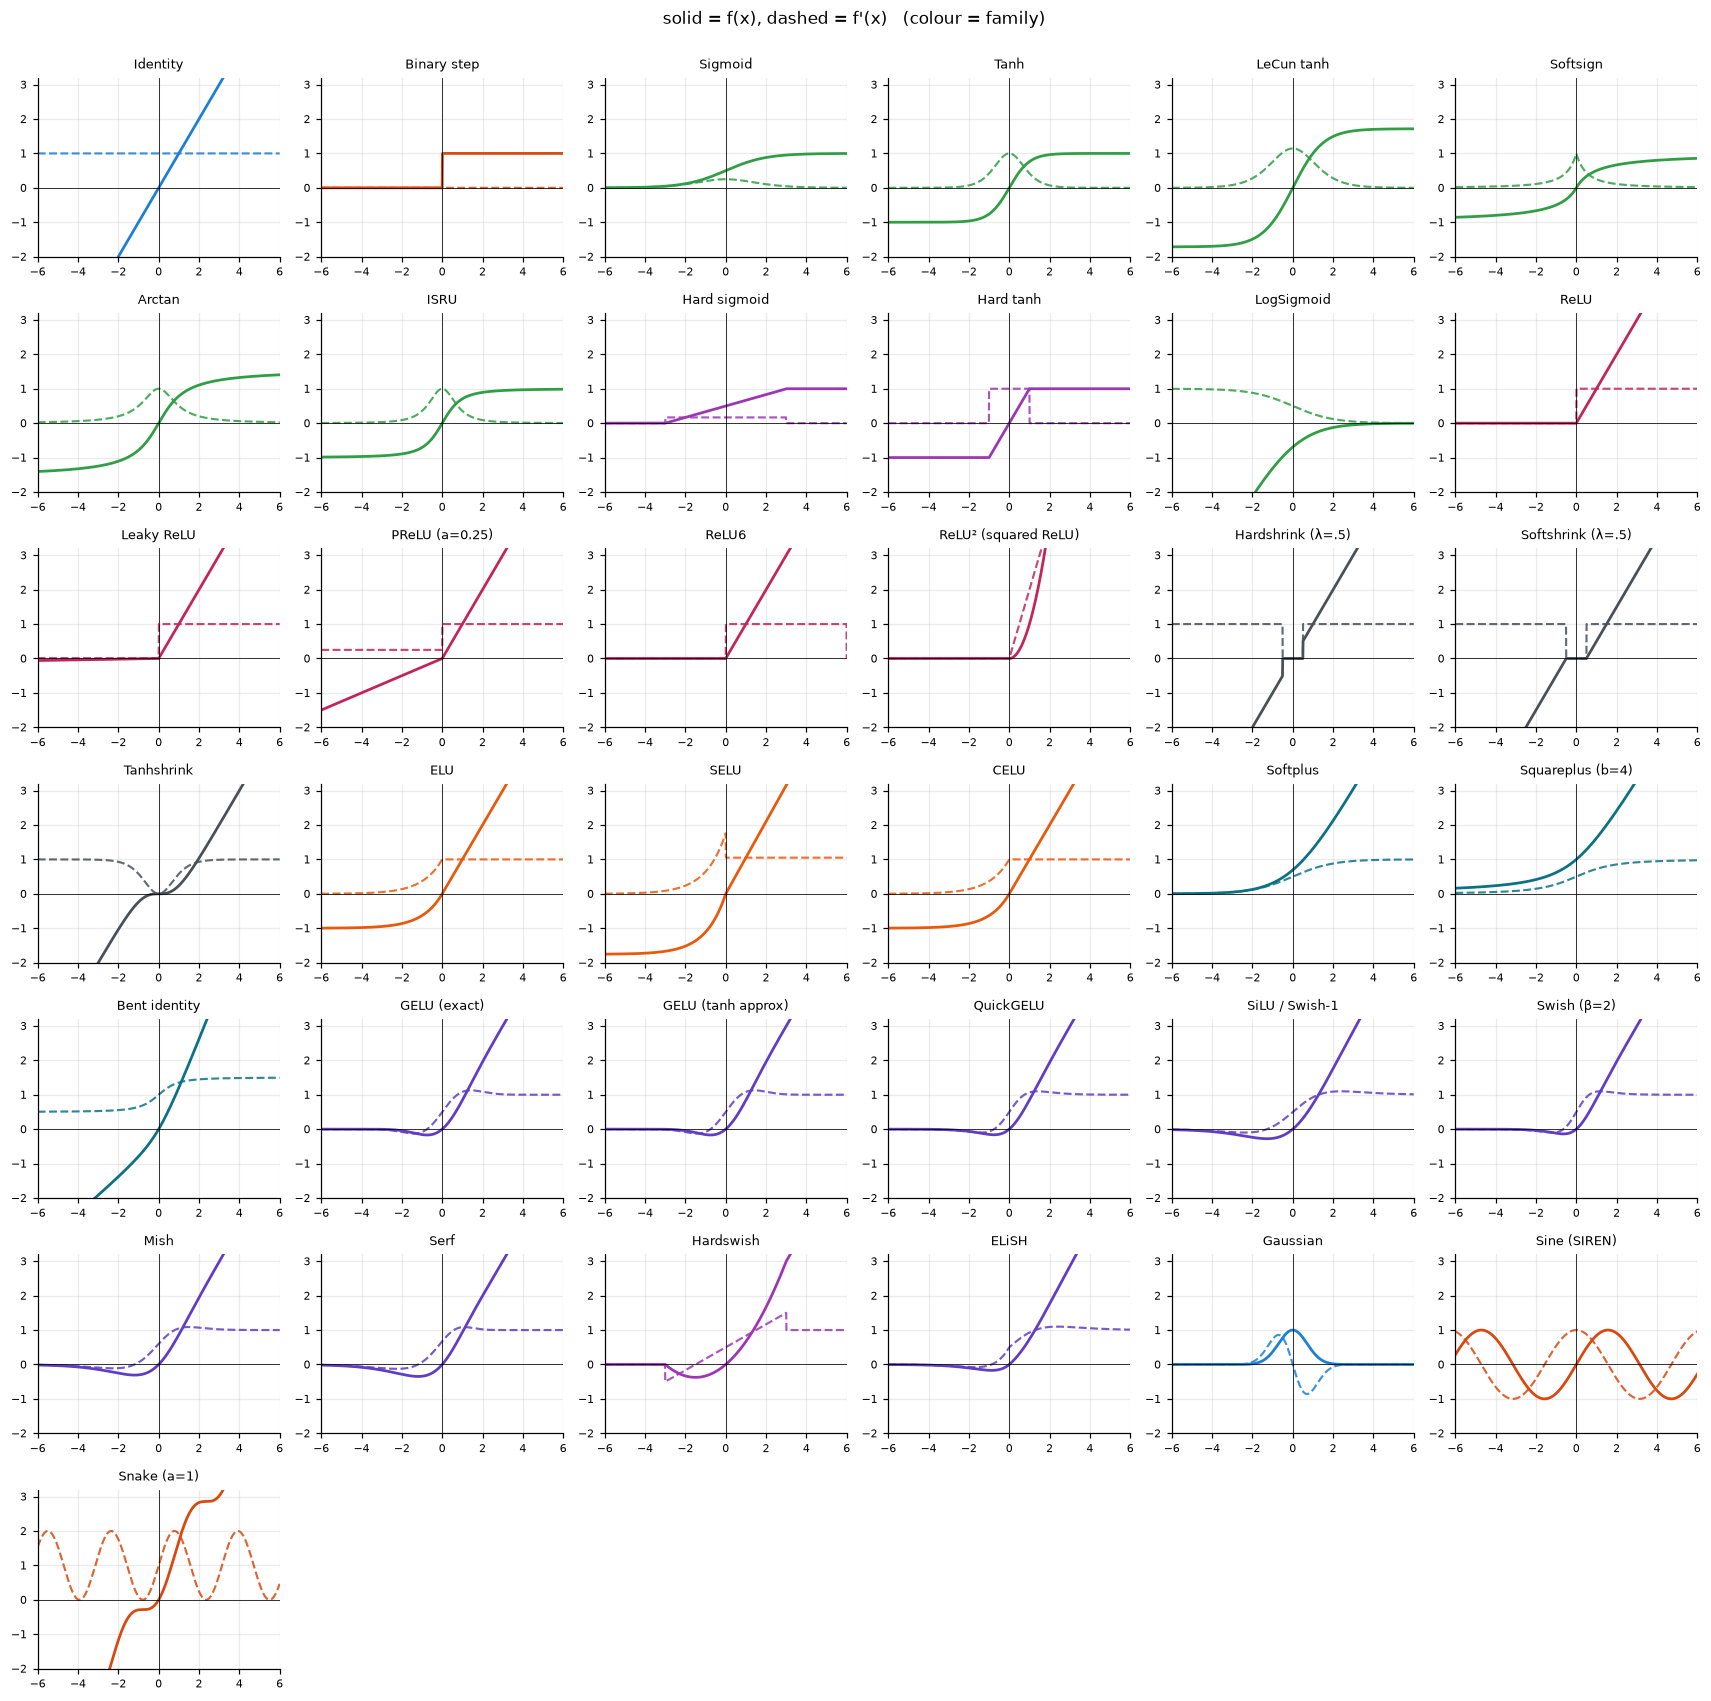

In [4]:
xp = torch.linspace(-6, 6, 1201)
n = len(R); cols = 6; rws = math.ceil(n/cols)
fig, axs = plt.subplots(rws, cols, figsize=(2.6*cols, 2.2*rws)); axs = axs.ravel()
FAMC = {}
pal = ["#1c7ed6","#d9480f","#2f9e44","#9c36b5","#c2255c","#495057","#e8590c","#0b7285","#5f3dc4"]
for i, (name, fam, f, df, formula, note) in enumerate(R):
    FAMC.setdefault(fam, pal[len(FAMC)%len(pal)])
    c = FAMC[fam]; ax = axs[i]
    ax.plot(xp, f(xp), color=c, lw=1.8); ax.plot(xp, df(xp), color=c, lw=1.4, ls="--", alpha=.85)
    ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
    ax.set_ylim(-2, 3.2); ax.set_xlim(-6, 6); ax.set_title(name, fontsize=8.5); ax.tick_params(labelsize=7)
for j in range(n, len(axs)): axs[j].axis("off")
fig.suptitle("solid = f(x), dashed = f'(x)   (colour = family)", y=1.0)
plt.tight_layout(); plt.show()

## Step 4 - The modern set, side by side

The activations that actually appear in current models. Left: `f(x)`. Right: `f'(x)`.

Things to see on the right-hand plot:

- **ReLU's** derivative is a hard 0/1 switch.
- **GELU, SiLU, Mish** have *smooth* derivatives that **overshoot 1** (to ≈1.13, ≈1.10, ≈1.09) before settling at 1 - the "bump".
- On the left, for `x < 0` GELU/SiLU/Mish **dip below zero** and come back: they are *non-monotonic*. That is the price for being smooth and is a feature, not a bug.

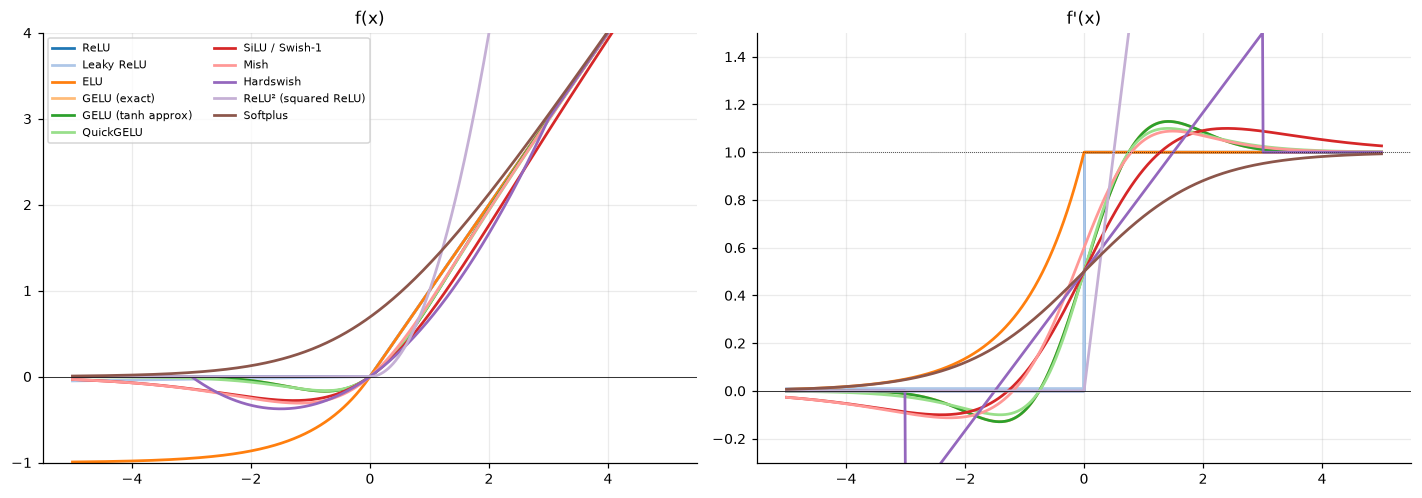

In [5]:
SOTA = ["ReLU","Leaky ReLU","ELU","GELU (exact)","GELU (tanh approx)","QuickGELU","SiLU / Swish-1","Mish","Hardswish","ReLU² (squared ReLU)","Softplus"]
cm = plt.get_cmap("tab20")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
xq = torch.linspace(-5, 5, 1001)
for i, nme in enumerate(SOTA):
    _, _, f, df, *_ = ACT[nme]
    a1.plot(xq, f(xq), color=cm(i), lw=1.8, label=nme); a2.plot(xq, df(xq), color=cm(i), lw=1.8, label=nme)
a1.set_ylim(-1, 4); a2.set_ylim(-0.3, 1.5); a1.set_title("f(x)"); a2.set_title("f'(x)")
a1.legend(fontsize=7, ncol=2); [a.axhline(0, color="k", lw=.5) for a in (a1, a2)]; a2.axhline(1, color="k", lw=.5, ls=":")
plt.tight_layout(); plt.show()

## Step 5 - Derivative facts worth knowing (all measured)

1. **Where is the minimum / max slope?** Sigmoid max slope is `0.25` (so 10 sigmoid layers can shrink a gradient by `0.25^10 ≈ 1e-6`). Tanh is `1`. ReLU is `1` on half the line.
2. **Swish/GELU/Mish overshoot** `f' > 1` - measured below.
3. **GELU at 0**: `f(0)=0`, `f'(0)=Φ(0)=0.5`. Same for SiLU (`σ(0)=0.5`). ReLU has no derivative there.
4. **Non-monotonic minimum**: location and depth of the dip.
5. **Swish's β** is learnable: `∂f/∂β = x² σ(βx)(1-σ(βx))`. Verified by autograd.
6. **Sigmoid/Tanh/SiLU/Softplus are *closed* under differentiation** (`f'` is written with `f`), which makes the backward pass reuse the forward value.

In [6]:
xf = torch.linspace(-8, 8, 160001)
print(f"{'activation':22s} {'max f\'':>8s} {'argmax':>8s} {'min f':>9s} {'at x':>8s} {'f\'(0)':>7s}")
facts = {}
for nme in ["Sigmoid","Tanh","ReLU","ELU","SELU","GELU (exact)","GELU (tanh approx)","SiLU / Swish-1","Mish","Serf","Hardswish","Softplus"]:
    _, _, f, df, *_ = ACT[nme]; y, d = f(xf), df(xf)
    im, ia = y.argmin(), d.argmax(); d0 = df(torch.tensor([0.0])).item()
    facts[nme] = (d.max().item(), xf[ia].item(), y.min().item(), xf[im].item(), d0)
    print(f"{nme:22s} {d.max().item():8.4f} {xf[ia].item():8.3f} {y.min().item():9.4f} {xf[im].item():8.3f} {d0:7.3f}")

check("sigmoid max slope is 0.25", abs(facts["Sigmoid"][0]-0.25) < 1e-9)
check("GELU f'(0)=0.5 and SiLU f'(0)=0.5", abs(facts["GELU (exact)"][4]-.5) < 1e-12 and abs(facts["SiLU / Swish-1"][4]-.5) < 1e-12)
check("GELU, SiLU, Mish all overshoot slope 1 (non-monotonic bump)", all(facts[k][0] > 1.0 for k in ["GELU (exact)","SiLU / Swish-1","Mish"]))
check("GELU, SiLU, Mish all dip below 0 (min < 0)", all(facts[k][2] < 0 for k in ["GELU (exact)","SiLU / Swish-1","Mish"]))
check("SiLU minimum ≈ -0.2785 at x≈-1.278", abs(facts["SiLU / Swish-1"][2]+0.2785) < 1e-3 and abs(facts["SiLU / Swish-1"][3]+1.278) < 2e-3)
# tanh-approx GELU vs exact
xx = torch.linspace(-8, 8, 20001)
e_f = (gelu_tanh(xx)-xx*Phi(xx)).abs().max().item(); e_d = (d_gelu_tanh(xx)-(Phi(xx)+xx*phi(xx))).abs().max().item()
print(f"\ntanh-GELU vs exact GELU: max |f diff| = {e_f:.2e}, max |f' diff| = {e_d:.2e}")
check("tanh-approx GELU matches exact within 1e-3 (f) and 1e-2 (f')", e_f < 1e-3 and e_d < 1e-2)
# swish beta gradient
b = torch.tensor(1.3, requires_grad=True); xb = torch.linspace(-4, 4, 41)
(g,) = torch.autograd.grad((xb*sig(b*xb)).sum(), b)
hand = (xb**2*sig(1.3*xb)*(1-sig(1.3*xb))).sum()
check("Swish ∂f/∂β = x² σ(βx)(1-σ(βx)) matches autograd", abs(g-hand).item() < 1e-10)
# PReLU slope grad
a_ = torch.tensor(0.25, requires_grad=True); (ga,) = torch.autograd.grad(torch.where(xb>0, xb, a_*xb).sum(), a_)
check("PReLU ∂f/∂a = min(x,0) matches autograd", abs(ga-torch.clamp(xb, max=0).sum()).item() < 1e-12)
# limits of swish
check("Swish β=50 ≈ ReLU,  β→0 gives x/2", (xb*sig(50*xb)-torch.relu(xb)).abs().max() < 0.02 and (xb*sig(1e-6*xb)-xb/2).abs().max() < 1e-5)

activation               max f'   argmax     min f     at x   f'(0)
Sigmoid                  0.2500   -0.000    0.0003   -8.000   0.250
Tanh                     1.0000   -0.000   -1.0000   -8.000   1.000
ReLU                     1.0000    0.000    0.0000   -8.000   0.000
ELU                      1.0000    0.000   -0.9997   -8.000   1.000
SELU                     1.7581   -0.000   -1.7575   -8.000   1.758
GELU (exact)             1.1289    1.414   -0.1700   -0.752   0.500
GELU (tanh approx)       1.1290    1.418   -0.1700   -0.752   0.500
SiLU / Swish-1           1.0998    2.399   -0.2785   -1.278   0.500
Mish                     1.0885    1.491   -0.3088   -1.192   0.600
Serf                     1.0861    1.096   -0.3484   -1.193   0.673
Hardswish                1.5000    3.000   -0.3750   -1.500   0.500
Softplus                 0.9997    8.000    0.0003   -8.000   0.500

tanh-GELU vs exact GELU: max |f diff| = 4.73e-04, max |f' diff| = 8.68e-04


## Step 6 - Gated units: GLU, ReGLU, GeGLU, SwiGLU

Almost every modern LLM feed-forward block (LLaMA, Qwen, Gemma, PaLM, OLMo ...) replaces `W₂·act(W₁x)` by a **gated** form (Shazeer 2020):

`FFN(x) = W₂ ( act(W_g x) ⊙ (W_u x) )`

Write `a = W_u x` (the *value* branch) and `b = W_g x` (the *gate* branch). Then `h(a, b) = a · g(b)` has **two** partial derivatives:

`∂h/∂a = g(b)`  &nbsp;&nbsp;  `∂h/∂b = a · g'(b)`

| name | gate `g` | note |
|---|---|---|
| GLU | σ | Dauphin 2017 |
| ReGLU | ReLU | |
| **GeGLU** | GELU | Gemma family |
| **SwiGLU** | SiLU | LLaMA, Qwen, PaLM, OLMo |
| Bilinear | identity | |

Because there are two branches, the hidden width is usually cut to `⅔·4d` to keep the parameter count equal to a plain MLP.

GLU       gate=Sigmoid           ∂/∂a err 0.0e+00   ∂/∂b err 1.1e-16
ReGLU     gate=ReLU              ∂/∂a err 0.0e+00   ∂/∂b err 0.0e+00
GeGLU     gate=GELU (exact)      ∂/∂a err 0.0e+00   ∂/∂b err 4.4e-16
SwiGLU    gate=SiLU / Swish-1    ∂/∂a err 0.0e+00   ∂/∂b err 4.4e-16
Bilinear  gate=Identity          ∂/∂a err 0.0e+00   ∂/∂b err 0.0e+00


/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_28760/4057449475.py:18: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  ax[1].quiver(A, B, dHa, dHb, np.hypot(dHa, dHb), cmap="viridis"); ax[1].set_title("gradient (∂h/∂a, ∂h/∂b)")


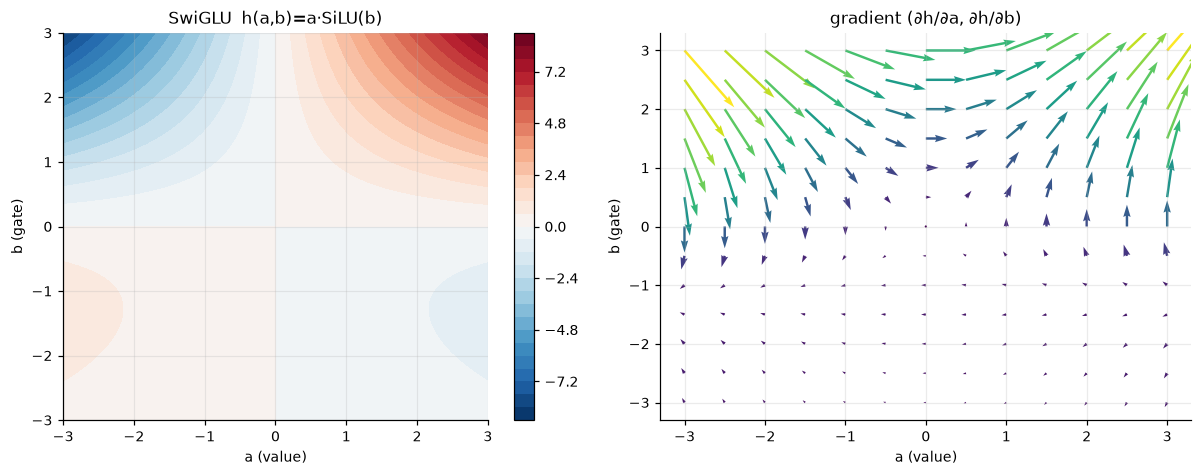

In [7]:
GATES = {"GLU": "Sigmoid", "ReGLU": "ReLU", "GeGLU": "GELU (exact)", "SwiGLU": "SiLU / Swish-1", "Bilinear": "Identity"}
a = torch.randn(4000); b = torch.randn(4000)
for glu, g in GATES.items():
    _, _, gf, gdf, *_ = ACT[g]
    aa = a.clone().requires_grad_(True); bb = b.clone().requires_grad_(True)
    out = aa*gf(bb); ga, gb = torch.autograd.grad(out.sum(), [aa, bb])
    e1 = (ga-gf(b)).abs().max().item(); e2 = (gb-a*gdf(b)).abs().max().item()
    print(f"{glu:9s} gate={g:16s}  ∂/∂a err {e1:.1e}   ∂/∂b err {e2:.1e}")
    check(f"{glu}: ∂h/∂a = g(b), ∂h/∂b = a·g'(b)", e1 < 1e-12 and e2 < 1e-10)

# picture: SwiGLU surface slice, h(a,b)=a*silu(b); gradients as arrows
A, B = torch.meshgrid(torch.linspace(-3, 3, 13), torch.linspace(-3, 3, 13), indexing="ij")
_, _, sf, sdf, *_ = ACT["SiLU / Swish-1"]
H = A*sf(B); dHa = sf(B); dHb = A*sdf(B)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
fine = torch.linspace(-3, 3, 200); AA, BB = torch.meshgrid(fine, fine, indexing="ij")
cs = ax[0].contourf(AA, BB, AA*sf(BB), 30, cmap="RdBu_r"); plt.colorbar(cs, ax=ax[0]); ax[0].set_title("SwiGLU  h(a,b)=a·SiLU(b)")
ax[1].quiver(A, B, dHa, dHb, np.hypot(dHa, dHb), cmap="viridis"); ax[1].set_title("gradient (∂h/∂a, ∂h/∂b)")
for x_ in ax: x_.set_xlabel("a (value)"); x_.set_ylabel("b (gate)")
plt.tight_layout(); plt.show()

## Step 7 - Vector-valued activations: softmax and maxout

Not every activation maps scalar → scalar.

**Softmax** `p_i = e^{z_i} / Σ_j e^{z_j}` couples all outputs. Its derivative is a **Jacobian matrix**:

`∂p_i/∂z_j = p_i (δ_ij − p_j)`  &nbsp;→&nbsp; `J = diag(p) − p pᵀ`

Properties: symmetric, rows sum to 0 (adding a constant to all logits changes nothing), rank `n−1`. With cross-entropy the whole chain collapses to `∂L/∂z = p − y`.

**Maxout** `max_k (w_k·x + b_k)` has derivative 1 for the winning piece and 0 for the others (a sub-gradient selector).

softmax p     : [0.011 0.119 0.039 0.263 0.285 0.283]
Jacobian row 0: [ 0.011 -0.001 -0.    -0.003 -0.003 -0.003]


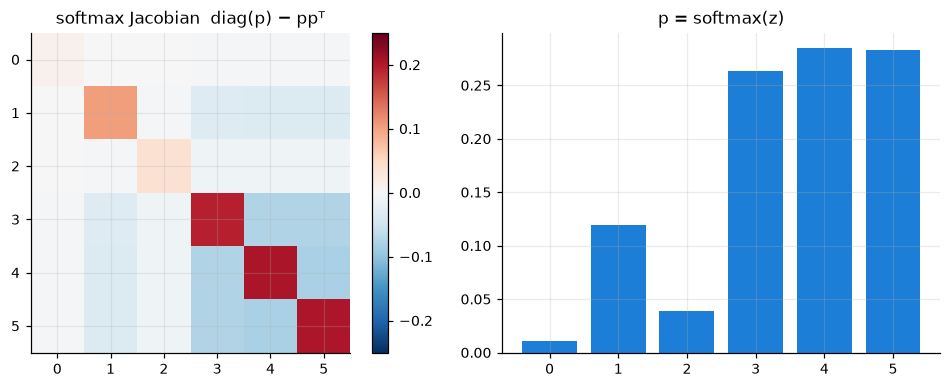

In [8]:
z = torch.randn(6)
p = torch.softmax(z, 0)
J_hand = torch.diag(p) - torch.outer(p, p)
J_auto = torch.autograd.functional.jacobian(lambda v: torch.softmax(v, 0), z)
check("softmax Jacobian diag(p)-ppᵀ == autograd Jacobian", (J_hand-J_auto).abs().max() < 1e-12)
check("softmax Jacobian symmetric, rows sum to 0, rank n-1", torch.allclose(J_hand, J_hand.T) and J_hand.sum(1).abs().max() < 1e-12 and torch.linalg.matrix_rank(J_hand) == 5)
y = torch.zeros(6); y[2] = 1
zz = z.clone().requires_grad_(True); (gz,) = torch.autograd.grad(F.cross_entropy(zz[None], torch.tensor([2])), zz)
check("softmax + cross-entropy gradient = p - y", (gz-(p-y)).abs().max() < 1e-12)
print("softmax p     :", np.round(p.numpy(), 3))
print("Jacobian row 0:", np.round(J_hand[0].numpy(), 3))

# maxout
W = torch.randn(3, 5, requires_grad=True); xin = torch.randn(5)
out = (W@xin).max(); (gW,) = torch.autograd.grad(out, W)
k = (W@xin).argmax()
check("maxout gradient flows only into the winning piece (∂/∂w_k = x, others 0)",
      torch.allclose(gW[k], xin) and gW[torch.arange(3) != k].abs().max() == 0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
im = ax[0].imshow(J_hand.numpy(), cmap="RdBu_r", vmin=-.25, vmax=.25); ax[0].set_title("softmax Jacobian  diag(p) − ppᵀ"); plt.colorbar(im, ax=ax[0])
ax[1].bar(range(6), p.numpy(), color="#1c7ed6"); ax[1].set_title("p = softmax(z)")
plt.tight_layout(); plt.show()

## Step 8 - Experiment A: gradient flow through a deep network

Take a plain 40-layer MLP (width 256, no residuals, no normalisation), He/Kaiming init (`σ_w² = 2/fan_in`, which assumes ReLU), and push gradients back from a loss on the output. For each activation we measure

`ratio_ℓ = ‖∂L/∂h_ℓ‖ / ‖∂L/∂h_40‖`

at every layer ℓ. `ratio ≈ 1` = healthy; `≪ 1` = **vanishing**; `≫ 1` = **exploding**.

This is a stress test, **not** a recommendation: real networks use residuals and norms that hide most of these differences. It isolates what each *derivative* does to the signal. The init is the same for all, so activations whose gain differs from ReLU's will drift. **Measured surprise:** SiLU and Hardswish lose ~5 orders of magnitude here while ReLU stays near 1 - not because they are bad, but because `σ_w²=2/fan_in` is ReLU's constant. SiLU/GELU shrink the signal's variance more than ReLU does (their `f` is smaller and their `f'` averages below 1 on the bulk of a Gaussian), so they need a larger init gain, or - in practice - LayerNorm/residuals, which absorb the mismatch. Exercise 3 asks you to compute that gain.

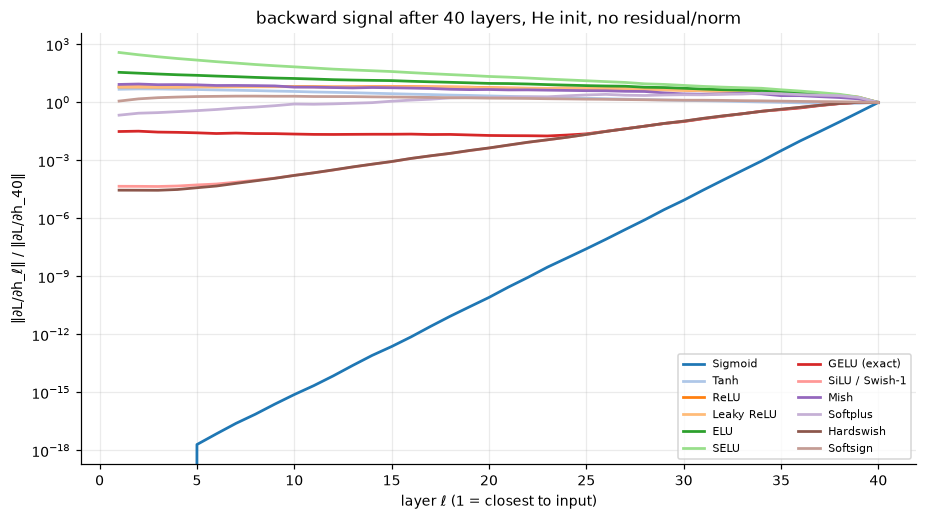

activation          grad ratio at layer 1
Sigmoid                         0.000e+00
Tanh                            4.809e+00
ReLU                            6.401e+00
Leaky ReLU                      6.261e+00
ELU                             3.618e+01
SELU                            3.851e+02
GELU (exact)                    3.146e-02
SiLU / Swish-1                  4.620e-05
Mish                            8.566e+00
Softplus                        2.202e-01
Hardswish                       2.904e-05
Softsign                        1.178e+00


/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_28760/3816096761.py:24: RuntimeWarning: divide by zero encountered in scalar divide
  check("sigmoid gradient vanishes (>1e4x smaller at layer 1 than ReLU)", FL["ReLU"][0]/FL["Sigmoid"][0] > 1e4)


In [9]:
torch.set_default_dtype(torch.float32)
def gradflow(actname, depth=40, width=256, seed=0):
    f = ACT[actname][2]
    g = torch.Generator().manual_seed(seed)
    Ws = [torch.randn(width, width, generator=g)*math.sqrt(2/width) for _ in range(depth)]
    x = torch.randn(512, width, generator=g).requires_grad_(True)
    hs = []; h = x
    for W in Ws:
        h = f(h@W.T); h.retain_grad(); hs.append(h)
    loss = (h**2).mean(); loss.backward()
    norms = torch.tensor([t.grad.norm().item() for t in hs])
    return (norms/norms[-1]).numpy()

TEST = ["Sigmoid","Tanh","ReLU","Leaky ReLU","ELU","SELU","GELU (exact)","SiLU / Swish-1","Mish","Softplus","Hardswish","Softsign"]
FL = {}
for nme in TEST:
    r = gradflow(nme); FL[nme] = r
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for i, nme in enumerate(TEST): ax.semilogy(np.arange(1, 41), FL[nme], color=plt.get_cmap("tab20")(i), lw=1.8, label=nme)
ax.set_xlabel("layer ℓ (1 = closest to input)"); ax.set_ylabel("‖∂L/∂h_ℓ‖ / ‖∂L/∂h_40‖"); ax.legend(fontsize=7, ncol=2)
ax.set_title("backward signal after 40 layers, He init, no residual/norm"); plt.tight_layout(); plt.show()
print(f"{'activation':18s} {'grad ratio at layer 1':>22s}")
for nme in TEST: print(f"{nme:18s} {FL[nme][0]:22.3e}")
check("sigmoid gradient vanishes (>1e4x smaller at layer 1 than ReLU)", FL["ReLU"][0]/FL["Sigmoid"][0] > 1e4)
check("ReLU, Leaky ReLU, Tanh keep the backward signal within 3 orders of magnitude of 1 over 40 layers (He init matches their gain)", all(1e-3 < FL[k][0] < 1e3 for k in ["ReLU","Leaky ReLU","Tanh"]))
check("with ReLU's He init, SiLU and Hardswish shrink the gradient >1e3x more than ReLU (init-gain mismatch, not a flaw of the activation)", all(FL["ReLU"][0]/FL[k][0] > 1e3 for k in ["SiLU / Swish-1","Hardswish"]))

## Step 9 - Experiment B: dead units, and a small training race

**Dead units.** A ReLU unit whose pre-activation is negative for *every* input has `f' = 0` there and never recovers. We initialise a 1-hidden-layer net with a **large negative bias** (a harsh but realistic situation after one bad update) and count units with `|∂f/∂z| < 1e-6` on all data. Smooth/leaky activations keep a non-zero slope.

**Training race.** Two-spiral classification, a 4-layer MLP (width 64), AdamW, identical seeds and data, 600 steps. Small and synthetic, so read it as a sanity check about *optimisation ease*, not a ranking of activations for LLMs.

activation            % units with zero slope on ALL inputs
ReLU                                                   83.6
ReLU6                                                  83.6
Leaky ReLU                                              0.0
ELU                                                     0.0
GELU (exact)                                            0.0
SiLU / Swish-1                                          0.0
Mish                                                    0.0
Softplus                                                0.0
Hardswish                                               0.0


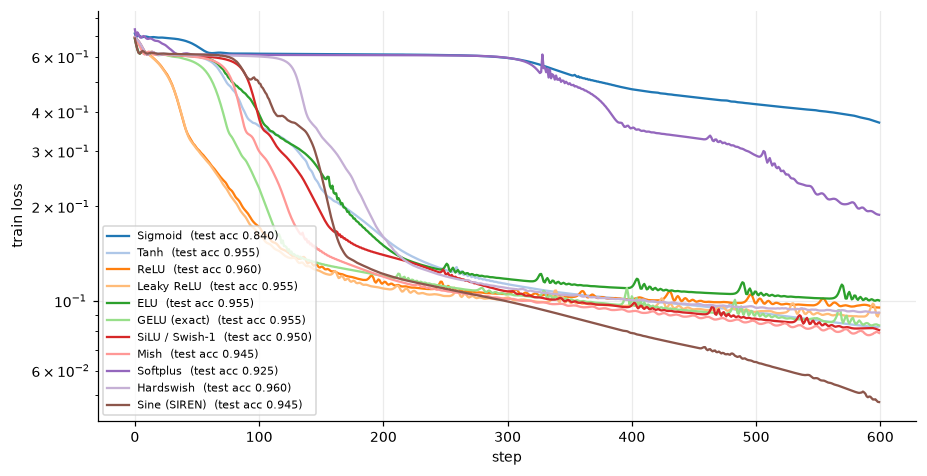

activation          final loss  test acc
Sigmoid                 0.3702     0.840
Tanh                    0.0830     0.955
ReLU                    0.0953     0.960
Leaky ReLU              0.0915     0.955
ELU                     0.1004     0.955
GELU (exact)            0.0836     0.955
SiLU / Swish-1          0.0807     0.950
Mish                    0.0790     0.945
Softplus                0.1882     0.925
Hardswish               0.0918     0.960
Sine (SIREN)            0.0476     0.945


In [10]:
# ---- dead units ----
torch.manual_seed(1)
X = torch.randn(2000, 32); Wd = torch.randn(256, 32)/math.sqrt(32)
z = X@Wd.T - 4.0                                            # harsh negative bias
print(f"{'activation':18s} {'% units with zero slope on ALL inputs':>40s}")
dead = {}
for nme in ["ReLU","ReLU6","Leaky ReLU","ELU","GELU (exact)","SiLU / Swish-1","Mish","Softplus","Hardswish"]:
    d = ACT[nme][3](z).abs().max(0).values < 1e-6
    dead[nme] = d.float().mean().item()*100; print(f"{nme:18s} {dead[nme]:40.1f}")
check("ReLU has dead units under negative bias, Leaky ReLU/Softplus/ELU have none", dead["ReLU"] > 20 and dead["Leaky ReLU"] == 0 and dead["Softplus"] == 0 and dead["ELU"] == 0)

# ---- spiral race ----
def spiral(n=500, noise=0.25, seed=0):
    g = torch.Generator().manual_seed(seed); t = torch.sqrt(torch.rand(n, generator=g))*3*math.pi
    a = torch.stack([t*torch.cos(t), t*torch.sin(t)], 1)/10; b = -a
    Xs = torch.cat([a, b])+noise*torch.randn(2*n, 2, generator=g)/3
    return Xs, torch.cat([torch.zeros(n), torch.ones(n)]).long()
Xs, ys = spiral(); perm = torch.randperm(len(Xs), generator=torch.Generator().manual_seed(3))
tr, te = perm[:800], perm[800:]

def train(actname, steps=600, seed=0):
    f = ACT[actname][2]; torch.manual_seed(seed)
    layers = [torch.nn.Linear(2, 64), torch.nn.Linear(64, 64), torch.nn.Linear(64, 64), torch.nn.Linear(64, 2)]
    ps = [p for l in layers for p in l.parameters()]; opt = torch.optim.AdamW(ps, 3e-3, weight_decay=0)
    losses = []
    def fwd(x):
        for l in layers[:-1]: x = f(l(x))
        return layers[-1](x)
    for s in range(steps):
        loss = F.cross_entropy(fwd(Xs[tr]), ys[tr]); opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    with torch.no_grad(): acc = (fwd(Xs[te]).argmax(1) == ys[te]).float().mean().item()
    return losses, acc

RACE = ["Sigmoid","Tanh","ReLU","Leaky ReLU","ELU","GELU (exact)","SiLU / Swish-1","Mish","Softplus","Hardswish","Sine (SIREN)"]
res = {n_: train(n_) for n_ in RACE}
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for i, n_ in enumerate(RACE): ax.plot(res[n_][0], color=plt.get_cmap("tab20")(i), lw=1.5, label=f"{n_}  (test acc {res[n_][1]:.3f})")
ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("train loss"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"{'activation':18s} {'final loss':>11s} {'test acc':>9s}")
for n_ in RACE: print(f"{n_:18s} {res[n_][0][-1]:11.4f} {res[n_][1]:9.3f}")
check("every activation trains (final loss < initial loss)", all(res[k][0][-1] < res[k][0][0] for k in RACE))
check("a smooth gate (GELU/SiLU/Mish) fits the spiral better than sigmoid in 600 steps", min(res[k][0][-1] for k in ["GELU (exact)","SiLU / Swish-1","Mish"]) < res["Sigmoid"][0][-1])

## Step 10 - The whole table, `f` and `f'`

Every activation in the catalogue with its formula (derivative is in the next column, derived by hand and verified in Step 2).

In [11]:
DERIV = {
"Identity": "1", "Binary step": "0 (a.e.)", "Sigmoid": "σ(x)(1−σ(x))", "Tanh": "1 − tanh²x", "LeCun tanh": "1.1439 (1 − tanh²(2x/3))",
"Softsign": "1/(1+|x|)²", "Arctan": "1/(1+x²)", "ISRU": "(1+αx²)^(−3/2)", "Hard sigmoid": "1/6 on (−3,3) else 0", "Hard tanh": "1 on (−1,1) else 0",
"LogSigmoid": "σ(−x)", "ReLU": "1[x>0]", "Leaky ReLU": "1 (x>0), 0.01", "PReLU (a=0.25)": "1 (x>0), a", "ReLU6": "1 on (0,6) else 0",
"ReLU² (squared ReLU)": "2·max(0,x)", "Hardshrink (λ=.5)": "1[|x|>λ]", "Softshrink (λ=.5)": "1[|x|>λ]", "Tanhshrink": "tanh²x",
"ELU": "1 (x>0), αeˣ", "SELU": "λ·(1 | αeˣ)", "CELU": "1 (x>0), e^(x/α)", "Softplus": "σ(x)", "Squareplus (b=4)": "½(1 + x/√(x²+b))",
"Bent identity": "x/(2√(x²+1)) + 1", "GELU (exact)": "Φ(x) + x·φ(x)", "GELU (tanh approx)": "½(1+t) + ½x(1−t²)√(2/π)(1+3·0.044715x²),  t=tanh(√(2/π)(x+0.044715x³))",
"QuickGELU": "σ(1.702x) + 1.702·xσ(1.702x)(1−σ(1.702x))", "SiLU / Swish-1": "σ(x)(1 + x(1−σ(x)))", "Swish (β=2)": "σ(βx) + βx σ(βx)(1−σ(βx))",
"Mish": "tanh(sp(x)) + x σ(x)(1 − tanh²(sp(x)))", "Serf": "erf(sp(x)) + x(2/√π)e^(−sp(x)²)σ(x)", "Hardswish": "0 (x<−3), (2x+3)/6, 1 (x>3)",
"ELiSH": "x≥0: σ(1+x(1−σ)); x<0: eˣσ + (eˣ−1)σ(1−σ)", "Gaussian": "−2x e^(−x²)", "Sine (SIREN)": "cos x", "Snake (a=1)": "1 + sin(2ax)",
}
miss = [r[0] for r in R if r[0] not in DERIV]; check("every registered activation has a derivative string in the table", not miss, str(miss))
print(f"{'#':>2s} {'activation':22s} {'family':12s} {'f(x)':58s} | f'(x)")
for i, (nme, fam, f, df, formula, note) in enumerate(R, 1): print(f"{i:2d} {nme:22s} {fam:12s} {formula:58s} | {DERIV[nme]}")

 # activation             family       f(x)                                                       | f'(x)
 1 Identity               linear       x                                                          | 1
 2 Binary step            classical    1[x>0]                                                     | 0 (a.e.)
 3 Sigmoid                saturating   1/(1+e^{-x})                                               | σ(x)(1−σ(x))
 4 Tanh                   saturating   tanh x                                                     | 1 − tanh²x
 5 LeCun tanh             saturating   1.7159\tanh(2x/3)                                          | 1.1439 (1 − tanh²(2x/3))
 6 Softsign               saturating   x/(1+|x|)                                                  | 1/(1+|x|)²
 7 Arctan                 saturating   \arctan x                                                  | 1/(1+x²)
 8 ISRU                   saturating   x/\sqrt{1+\alpha x^2}                                      | (1+αx²)^(−3/2)

In [12]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n_, ok, d) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n_}")
failed = [n_ for n_, ok, _ in CHECKS if not ok]
print(f"\n{len(CHECKS)-len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    d/dx Identity: hand == autograd (max err 0.0e+00) and == finite diff (1.4e-10)
 2  PASS    d/dx Binary step: hand == autograd (max err 0.0e+00) and == finite diff (0.0e+00)
 3  PASS    d/dx Sigmoid: hand == autograd (max err 0.0e+00) and == finite diff (1.4e-10)
 4  PASS    d/dx Tanh: hand == autograd (max err 4.9e-17) and == finite diff (8.2e-11)
 5  PASS    d/dx LeCun tanh: hand == autograd (max err 2.2e-16) and == finite diff (2.1e-10)
 6  PASS    d/dx Softsign: hand == autograd (max err 2.2e-16) and == finite diff (1.4e-10)
 7  PASS    d/dx Arctan: hand == autograd (max err 0.0e+00) and == finite diff (1.2e-10)
 8  PASS    d/dx ISRU: hand == autograd (max err 2.2e-16) and == finite diff (1.6e-10)
 9  PASS    d/dx Hard sigmoid: hand == autograd (max err 0.0e+00) and == finite diff (8.8e-11)
10  PASS    d/dx Hard tanh: hand == autograd (max err 0.0e+00) and == finite diff (2.9e-11)
11  PASS    d/dx LogSigmoid: hand == autograd (max err 2.2e-16) and == fi

## Cheat sheet

| need | pick | why (derivative view) |
|---|---|---|
| default CNN / small MLP | **ReLU / Leaky ReLU** | `f'∈{0,1}`: no shrinkage, free to compute; dead units possible |
| transformer FFN, plain | **GELU** (exact or tanh) | smooth `f'`, `f'(0)=0.5`, slight overshoot |
| transformer FFN, modern LLM | **SwiGLU / GeGLU** | gate × value: `∂/∂a = g(b)`, `∂/∂b = a·g'(b)` |
| vision, YOLO-style | **SiLU / Mish** | smooth, non-monotonic, `f'` up to ≈1.1 |
| mobile / int8 | **Hardswish, ReLU6** | piecewise-linear, no `exp` |
| self-normalising MLP | **SELU** (+ LeCun init, alpha-dropout) | `λ·α` chosen so mean/var are fixed points |
| implicit neural reps | **Sine, Snake** | periodic, `f'` also periodic; needs special init |
| output probabilities | **Softmax / Sigmoid** | Jacobian `diag(p)−ppᵀ`; with CE gives `p−y` |
| never | sigmoid/tanh deep in a plain stack | max slope 0.25 / saturates -> vanishing |

## Exercises
1. Add **SMELU**, **Softexp**, **ShiftedSoftplus** and **ReLU-with-a-leak-schedule**; derive `f'` by hand and plug them into the Step-2 checker.
2. Derive the **second derivative** of GELU, `f'' = 2φ(x) − x²φ(x)`, and verify with `torch.autograd.functional.hessian`. Why does a smooth `f''` matter for second-order optimisers?
3. Compute `E[f'(z)²]` for `z~N(0,1)` for each activation - this is the per-layer gain of the backward signal. Which init constant makes it 1 for GELU/SiLU?
4. Replace the 40-layer MLP of Step 8 by one with residual connections + LayerNorm and see how much of the difference disappears.

## Honest limits
- Derivatives are verified in **float64** against autograd and finite differences at points away from kinks; at the kinks themselves (ReLU at 0 etc.) the value is a **convention** (PyTorch uses 0 for ReLU).
- Steps 8-9 use synthetic data and small nets (random-feature gradient flow; two spirals). They show the *mechanism*, not which activation wins in a real LLM - residual streams, normalisation and the optimiser change the picture a lot.
- The "used in" notes (BERT, LLaMA, Gemma, YOLOv4, MobileNetV3 ...) are recalled from the papers/model cards and were **not** re-checked against model code in this session.
- Several activations (Serf, ELiSH, Snake, LeCun tanh) are included for completeness; they are not mainstream today.